# Gaussian Noise 추가 — Open QSM Dataset

`01_Load_data_Open_QSM_Dataset_EchoSeparated.ipynb`에서 복원한 **5-echo complex GRE** 데이터에
synthetic complex Gaussian noise를 추가하여 **10%, 30%, 50% noise level**의 실험 데이터를 생성한다.

이번 실험에서는 complex MRI의 noise model을 반영하여 **Real 성분과 Imaginary 성분에 서로 독립적인
zero-mean Gaussian noise**를 추가한다.

원본 complex 데이터는 변경하지 않고, noise가 추가된 데이터만 별도로 저장한다.


In [2]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from pathlib import Path


## 환경설정

`01_Load_data`에서 `SAVE_PROCESSED = True`로 실행하면 생성되는 `.npz` 파일을 입력으로 사용한다.

같은 `SEED`를 각 noise level에서 다시 사용하므로 10%, 30%, 50% 실험은
**동일한 random noise pattern을 크기만 다르게 scaling**하여 비교하게 된다.


In [4]:
PROCESSED_PATH = Path(
    "./data/processed/qsm_consensus_siemens_monopolar_complex.npz"
)

NOISE_LEVELS = [0.1, 0.3, 0.5]
SEED = 42

OUT_DIR = Path("./data/noisy_data")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 필요할 때만 MATLAB 호환 .mat 파일도 추가 저장
SAVE_MAT_COMPAT = False

print("Input :", PROCESSED_PATH)
print("Output:", OUT_DIR)


Input : data\processed\qsm_consensus_siemens_monopolar_complex.npz
Output: data\noisy_data


## 1. Complex GRE 데이터 불러오기

입력 데이터의 예상 구조는 다음과 같다.

- `meas_gre`: `(X, Y, Z, 5)` complex array
- `mask_brain`: `(X, Y, Z)` boolean mask
- `echo_times`: 5개 echo time
- `field_strength`: MRI field strength


In [6]:
if not PROCESSED_PATH.exists():
    raise FileNotFoundError(
        f"{PROCESSED_PATH} 파일이 없습니다.\n"
        "먼저 01_Load_data 노트북에서 SAVE_PROCESSED = True로 설정한 뒤 실행하세요."
    )

data = np.load(PROCESSED_PATH, allow_pickle=False)

meas_gre = data["meas_gre"].astype(np.complex64)
mask = data["mask_brain"].astype(bool)

echo_times = (
    data["echo_times"].astype(np.float64)
    if "echo_times" in data.files
    else np.full(meas_gre.shape[-1], np.nan, dtype=np.float64)
)

field_strength = (
    float(data["field_strength"])
    if "field_strength" in data.files
    else np.nan
)

if meas_gre.ndim != 4:
    raise ValueError(f"meas_gre는 4D여야 합니다. 현재 shape={meas_gre.shape}")

if mask.shape != meas_gre.shape[:3]:
    raise ValueError(
        f"mask shape {mask.shape} != spatial shape {meas_gre.shape[:3]}"
    )

if not np.iscomplexobj(meas_gre):
    raise TypeError("meas_gre가 complex array가 아닙니다.")

n_echoes = meas_gre.shape[-1]

print("meas_gre shape :", meas_gre.shape)
print("meas_gre dtype :", meas_gre.dtype)
print("mask shape     :", mask.shape)
print("mask voxels    :", np.sum(mask))
print("n_echoes       :", n_echoes)
print("echo_times [s] :", echo_times)
print("field strength :", field_strength, "T")


meas_gre shape : (176, 256, 144, 5)
meas_gre dtype : complex64
mask shape     : (176, 256, 144)
mask voxels    : 2899729
n_echoes       : 5
echo_times [s] : [0.00525 0.01108 0.01691 0.02274 0.02857]
field strength : 3.0 T


## 2. Brain mask 내부 평균 magnitude 계산

Noise scale은 brain mask 내부의 원본 magnitude 평균을 기준으로 정의한다.

각 echo의 평균 magnitude를 먼저 계산한 뒤, 5개 echo의 평균값을 다시 평균하여
전체 기준 신호 크기 \( \bar{M} \)를 계산한다.

Noise level이 \(r\)일 때 Real/Imaginary 각 성분의 표준편차는

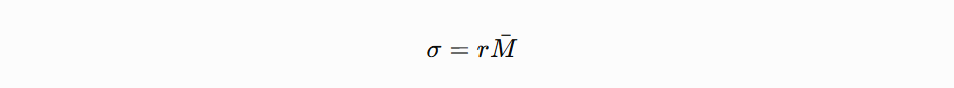

으로 정의한다.

> 여기서 10%, 30%, 50%는 **Real/Imaginary 각 성분에 적용되는 Gaussian noise의
> 표준편차 \(\sigma\)**가 평균 magnitude의 몇 %인지 나타낸다.


In [8]:
mean_signals = []

for e in range(n_echoes):
    mag_echo = np.abs(meas_gre[..., e])
    brain_region = mag_echo[mask]
    mean_signals.append(float(brain_region.mean()))

overall_mean = float(np.mean(mean_signals))

print("===== Echo별 brain-mask 내부 평균 magnitude =====")
for e, value in enumerate(mean_signals, start=1):
    print(f"Echo {e}: {value:.6f}")

print(f"\n전체 echo 평균 magnitude: {overall_mean:.6f}")


===== Echo별 brain-mask 내부 평균 magnitude =====
Echo 1: 376.541595
Echo 2: 294.131775
Echo 3: 249.395660
Echo 4: 212.976349
Echo 5: 177.971573

전체 echo 평균 magnitude: 262.203391


## 3. 10%, 30%, 50% Complex Gaussian Noise 생성

원본 complex signal을

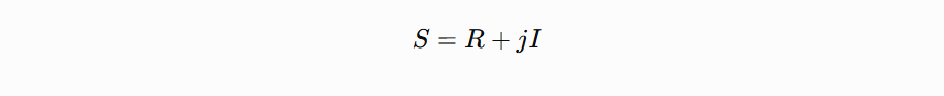

라고 하면 noisy signal은

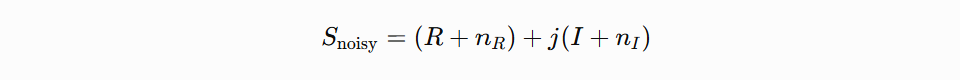
로 생성한다.

여기서

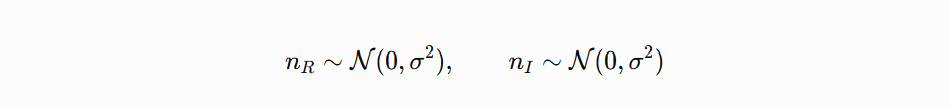

이며 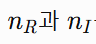는 서로 독립이다.

현재 실험 설계와 동일하게 **brain mask 내부에만 noise를 추가**한다.


In [10]:
results = {}

for noise_ratio in NOISE_LEVELS:
    # 같은 seed를 다시 사용하여 noise level 간 동일한 spatial pattern 유지
    rng = np.random.default_rng(SEED)

    sigma = overall_mean * noise_ratio
    noise_percent = int(round(noise_ratio * 100))

    print("\n" + "=" * 55)
    print(f"Noise level       : {noise_percent}%")
    print(f"Sigma/component   : {sigma:.6f}")
    print(f"Seed              : {SEED}")
    print("=" * 55)

    noisy_complex = np.empty_like(meas_gre, dtype=np.complex64)

    for e in range(n_echoes):
        orig_echo = meas_gre[..., e]

        noise_real = rng.normal(
            loc=0.0,
            scale=sigma,
            size=orig_echo.shape
        ).astype(np.float32)

        noise_imag = rng.normal(
            loc=0.0,
            scale=sigma,
            size=orig_echo.shape
        ).astype(np.float32)

        # 기존 실험과 동일하게 brain mask 내부에만 noise 추가
        noise_complex = (
            noise_real + 1j * noise_imag
        ).astype(np.complex64)

        noisy_echo = orig_echo.copy()
        noisy_echo[mask] = (
            orig_echo[mask] + noise_complex[mask]
        )

        noisy_complex[..., e] = noisy_echo

    results[noise_percent] = {
        "noisy_complex": noisy_complex,
        "noise_ratio": float(noise_ratio),
        "sigma": float(sigma),
    }

    print(f"{noise_percent}% noise 생성 완료")

print("\n모든 noise level 생성 완료")



Noise level       : 10%
Sigma/component   : 26.220339
Seed              : 42
10% noise 생성 완료

Noise level       : 30%
Sigma/component   : 78.661017
Seed              : 42
30% noise 생성 완료

Noise level       : 50%
Sigma/component   : 131.101695
Seed              : 42
50% noise 생성 완료

모든 noise level 생성 완료


## 4. Noise 데이터 저장

기본 저장 형식은 `.npz`이다.

각 파일에는 denoising 실험에 필요한 다음 정보를 함께 저장한다.

- `noisy_complex`
- `mask_brain`
- `noise_ratio`
- `sigma`
- `seed`
- `overall_mean`
- `echo_times`
- `field_strength`


In [12]:
for noise_percent, result in results.items():
    output_path = OUT_DIR / (
        f"qsm_siemens_monopolar_noisy_{noise_percent}.npz"
    )

    np.savez_compressed(
        output_path,
        noisy_complex=result["noisy_complex"],
        mask_brain=mask.astype(bool),
        noise_ratio=np.float32(result["noise_ratio"]),
        sigma=np.float32(result["sigma"]),
        seed=np.int32(SEED),
        overall_mean=np.float32(overall_mean),
        echo_times=np.asarray(echo_times, dtype=np.float64),
        field_strength=np.float32(field_strength),
    )

    print("NPZ 저장 완료 ->", output_path)

    if SAVE_MAT_COMPAT:
        mat_path = OUT_DIR / (
            f"qsm_siemens_monopolar_noisy_{noise_percent}.mat"
        )

        sio.savemat(
            mat_path,
            {
                "noisy_complex": result["noisy_complex"],
                "mask_brain": mask.astype(np.uint8),
                "noise_ratio": result["noise_ratio"],
                "sigma": result["sigma"],
                "seed": SEED,
                "overall_mean": overall_mean,
                "echo_times": np.asarray(echo_times, dtype=np.float64),
                "field_strength": field_strength,
            }
        )

        print("MAT 저장 완료 ->", mat_path)

print("\n모든 파일 저장 완료")


NPZ 저장 완료 -> data\noisy_data\qsm_siemens_monopolar_noisy_10.npz
NPZ 저장 완료 -> data\noisy_data\qsm_siemens_monopolar_noisy_30.npz
NPZ 저장 완료 -> data\noisy_data\qsm_siemens_monopolar_noisy_50.npz

모든 파일 저장 완료


## 5. 결과 확인

Echo 1의 중앙 slice에서 Original / Noisy / Difference / Brain Mask를 비교한다.


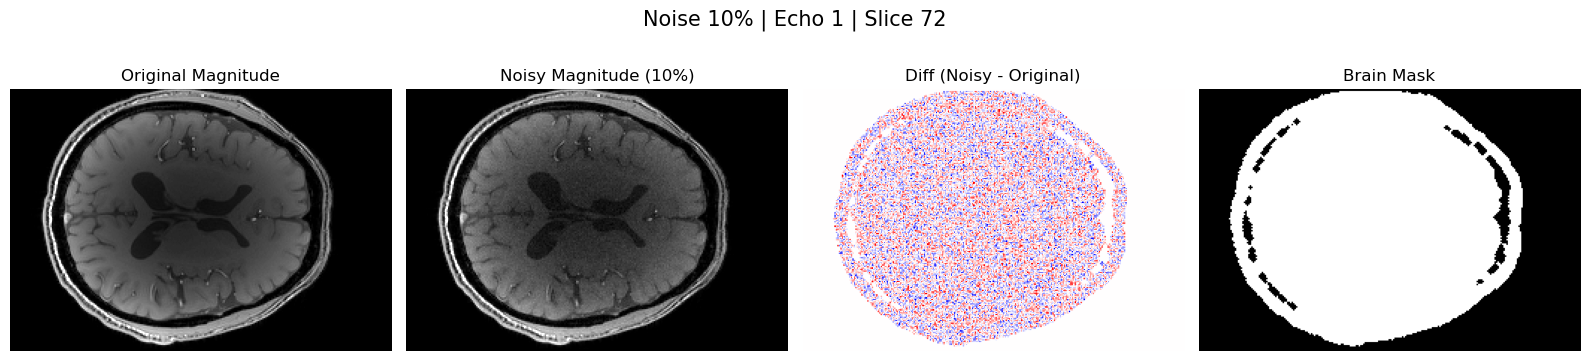

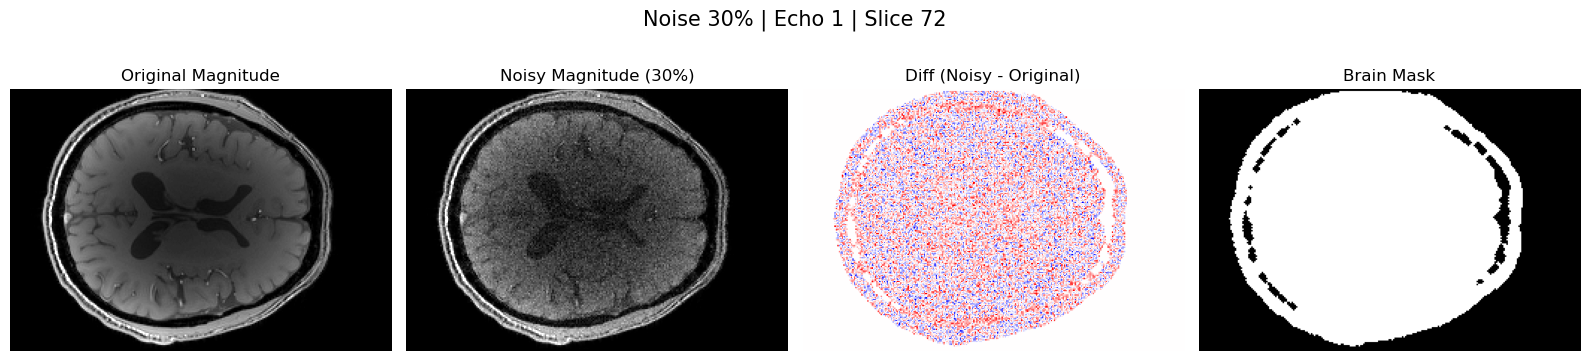

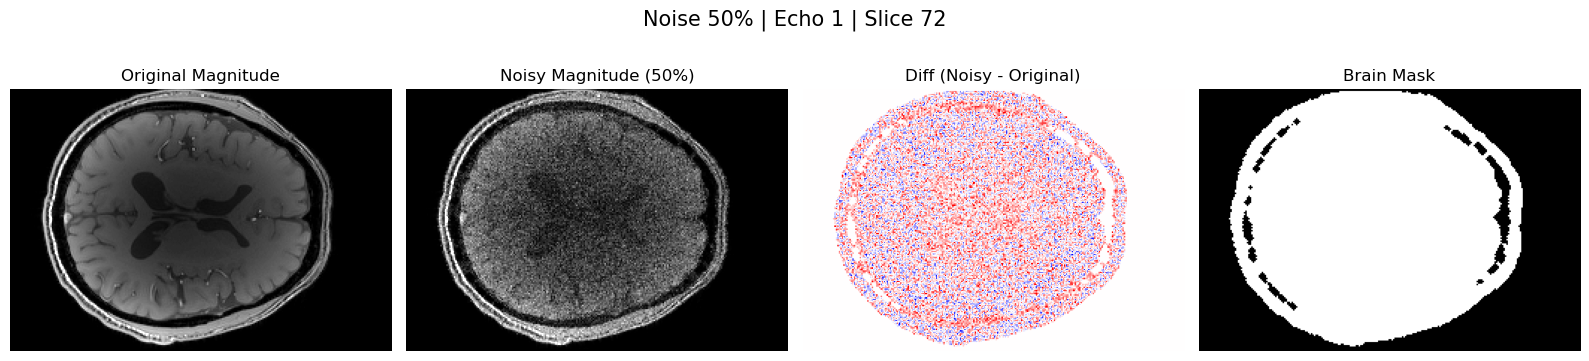

In [14]:
echo_idx = 0
slice_idx = meas_gre.shape[2] // 2

orig_mag = np.abs(meas_gre).astype(np.float32)

for noise_percent in [10, 30, 50]:
    noisy_complex = results[noise_percent]["noisy_complex"]
    noisy_mag = np.abs(noisy_complex).astype(np.float32)

    orig_2d = orig_mag[:, :, slice_idx, echo_idx]
    noisy_2d = noisy_mag[:, :, slice_idx, echo_idx]
    mask_2d = mask[:, :, slice_idx]

    diff_2d = noisy_2d - orig_2d

    brain_values = orig_mag[..., echo_idx][mask]
    vmin, vmax = np.percentile(brain_values, (1, 99))

    if np.any(mask_2d):
        dv = np.percentile(np.abs(diff_2d[mask_2d]), 99)
    else:
        dv = np.percentile(np.abs(diff_2d), 99)

    dv = max(float(dv), 1e-8)

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))

    ax[0].imshow(orig_2d, cmap="gray", vmin=vmin, vmax=vmax)
    ax[0].set_title("Original Magnitude")

    ax[1].imshow(noisy_2d, cmap="gray", vmin=vmin, vmax=vmax)
    ax[1].set_title(f"Noisy Magnitude ({noise_percent}%)")

    ax[2].imshow(diff_2d, cmap="bwr", vmin=-dv, vmax=dv)
    ax[2].set_title("Diff (Noisy - Original)")

    ax[3].imshow(mask_2d, cmap="gray")
    ax[3].set_title("Brain Mask")

    for a in ax:
        a.axis("off")

    fig.suptitle(
        f"Noise {noise_percent}% | Echo {echo_idx + 1} | Slice {slice_idx}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


## 6. 생성 결과 요약


In [16]:
print("===== Noise dataset summary =====")
print("Original shape :", meas_gre.shape)
print("Number echoes  :", n_echoes)
print("Mask voxels    :", np.sum(mask))
print("Mean magnitude :", overall_mean)
print()

for noise_percent in [10, 30, 50]:
    r = results[noise_percent]
    print(
        f"{noise_percent:>2}% | "
        f"sigma/component = {r['sigma']:.6f} | "
        f"dtype = {r['noisy_complex'].dtype}"
    )


===== Noise dataset summary =====
Original shape : (176, 256, 144, 5)
Number echoes  : 5
Mask voxels    : 2899729
Mean magnitude : 262.20339050292966

10% | sigma/component = 26.220339 | dtype = complex64
30% | sigma/component = 78.661017 | dtype = complex64
50% | sigma/component = 131.101695 | dtype = complex64
